## Stiff differential equations

A system is stiff when some of its components change on time scales far shorter than the one of interest: an explicit solver like `ode45` must take tiny steps to stay stable, while an implicit one like `ode15s` takes steps sized to the solution. Robertson's chemical reaction has rate constants from $0.04$ to $3 \times 10^7$:

$$y_1' = -0.04 y_1 + 10^4 y_2 y_3, \quad y_2' = 0.04 y_1 - 10^4 y_2 y_3 - 3 \cdot 10^7 y_2^2, \quad y_3' = 3 \cdot 10^7 y_2^2$$

359 steps; the masses still sum to 1.000000000000


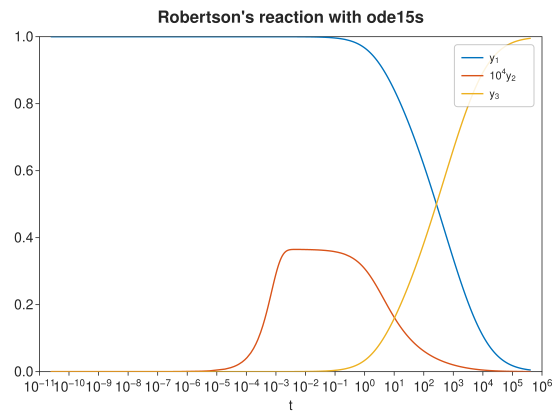

In [ ]:
rob = @(t, y) [-0.04*y(1) + 1e4*y(2)*y(3); 0.04*y(1) - 1e4*y(2)*y(3) - 3e7*y(2)^2; 3e7*y(2)^2];
[t, y] = ode15s(rob, [0 4e5], [1; 0; 0], odeset('RelTol', 1e-6, 'AbsTol', 1e-10));
semilogx(t(2:end), y(2:end, 1), t(2:end), 1e4*y(2:end, 2), t(2:end), y(2:end, 3))
legend('y_1', '10^4 y_2', 'y_3'), xlabel('t'), title('Robertson''s reaction with ode15s')
fprintf('%d steps; the masses still sum to %.12f\n', numel(t) - 1, sum(y(end, :)))

The van der Pol oscillator $y'' = \mu (1 - y^2) y' - y$ is stiff for large $\mu$: long slow stretches broken by sudden jumps. The solution structure's statistics show how few steps the stiff solvers need; `deval` evaluates the solution anywhere:

In [ ]:
mu = 1000; vdp = @(t, y) [y(2); mu*(1 - y(1)^2)*y(2) - y(1)];
for solver = {@ode15s, @ode23s}
    sol = solver{1}(vdp, [0 3000], [2; 0]);
    fprintf('%s: %d steps, y(3000) = %.4f\n', sol.solver, sol.stats.nsteps, deval(sol, 3000, 1))
end

ode15s: 559 steps, y(3000) = -1.4969


ode23s: 745 steps, y(3000) = -1.5137


With a mass matrix $M$, the solvers take $M y' = f(t, y)$; a singular $M$ makes some equations algebraic, a differential-algebraic system. Here $y_1' = -y_1 + y_2$ while $y_1 + y_2 = 1$ holds at every step:

In [ ]:
M = [1 0; 0 0]; f = @(t, y) [-y(1) + y(2); y(1) + y(2) - 1];
[t, y] = ode15s(f, [0 3], [0; 1], odeset('Mass', M, 'RelTol', 1e-6));
fprintf('y1(3) = %.6f (exact %.6f); largest |y1 + y2 - 1| = %.1e\n', y(end, 1), (1 - exp(-6))/2, max(abs(sum(y, 2) - 1)))

y1(3) = 0.498760 (exact 0.498761); largest |y1 + y2 - 1| = 1.1e-16
